# Homework 6: Linear Regression Modleing and Diagnostics
Build a predictive model for life expectancy using scikit-learn and perform a diagnostic audit to ensure the model’s coefficients are stable and mathematically sound.

## Task 1: Baseline Modeling
Load the WHO Life Expectancy Dataset, remove non-numeric columns (Country, Year), Convert Status column to  numeric, handle missing values.
- Use StandardScaler from sklearn.preprocessing to scale all independent variables. ("Life expectancy" is dependent variable) 
- Train a LinearRegression model using the scaled features.
- Report the R-Squared Score.
- Coefficient Analysis: Rank the features by their absolute coefficient values. Because the data is scaled, the largest coefficient now represents the most important predictor.

## Task 2: Iterative Diagnostic (VIF < 5)
Before analyzing the data, you must understand the Variance Inflation Factor (VIF) diagnostic. VIF measures multicollinearity, the degree to which your predictors are redundant.
High multicollinearity inflates the variance of coefficients, making them unreliable and difficult to interpret.
VIF is calculated by regressing one predictor against all others, then you obtain R_Squared and then compute VIF = 1/(1-R_Squared)
You sohuld use a cutoff of 5. Any variable with a VIF > 5 is considered too redundant and will be removed to improve the model's structural integrity. To do that follow the instruction below:

### Write a loop to iteratively remove the most redundant feature:
    1. Calculate VIF for every feature in the scaled dataset.
    2. Find the variable with the highest VIF.
    3. If VIF > 5, remove that feature from the data.
    4. Repeats the process until all remaining features have a VIF < 5
    - Note that in each iteration you remove only the highest VIF if it is greatet than 5!
    
## Task 3: Comparison of Model Results
    - Train a new LinearRegression model using only the independent features that survived the VIF diagnostic test.
    - Report the R-Squared Score.
    - Coefficient Analysis: Rank the features by their absolute coefficient values. Because the data is scaled, the largest coefficient now represents the most important predictor.
    - Are the top 5 predicotrs remain the same as those of the Baseline Model?

## Task 4: Residual Analysis and Normality
A good regression model should have errors (residuals) that are normally distributed and centered around zero.

    - Generate a histogram of the residuals for your baseline and clean model side by side.
    - Does the error distributions look like a bell curve?

## Task 5: The Interaction Investigation
In the real world application, the effect of one variable often depends on another. This is called an interaction.

    - Select two variables of your choice from the dataset (only variables with VIF < 5) that you believe might have a combined effect (e.g., Alcohol and GDP, or BMI and HIV/AIDS,). Write one sentence explaining why you think they interact.
    - Create a new column in your dataframe by multiplying these two variables together.
    - Train a new model by adding this new interaction term to your dataset and fit it again using LinearRegression.
    - Report the R-Squared Score.
    - Is the interaction coeficient positive or negative? Has adding it improved the Model performance?




### TASK 1

In [59]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression

df = pd.read_csv("Life_Expectancy_Data.csv")
df.columns = df.columns.str.strip()
df_numerical = df.select_dtypes(include=['number'])
df_numerical.dropna()

y = df_numerical['Life expectancy']
X = df_numerical.drop(columns=['Life expectancy'])

scaler = StandardScaler()
scaled_X = scaler.fit_transform(X)

lin_reg_model = LinearRegression().fit(scaled_X, y)
r2_score = lin_reg_model.score(scaled_X, y)
print(f"Baseline R-squared: {r2_score:.4f}")
feature_rank = pd.DataFrame({
    "Feature": X.columns,  
    "Coefficient": lin_reg_model.coef_,
    "Absolute Coefficient": np.abs(lin_reg_model.coef_) 
}).sort_values('Absolute Coefficient', ascending=False)
print(feature_rank)

Baseline R-squared: 0.8379
                            Feature  Coefficient  Absolute Coefficient
8                 under-five deaths   -10.853719             10.853719
2                     infant deaths    10.729025             10.729025
12                         HIV/AIDS    -2.710781              2.710781
18                        Schooling     2.532682              2.532682
1                   Adult Mortality    -2.059028              2.059028
17  Income composition of resources     1.916368              1.916368
7                               BMI     0.623113              0.623113
4            percentage expenditure     0.546340              0.546340
0                              Year    -0.530730              0.530730
3                           Alcohol    -0.396010              0.396010
13                              GDP     0.338454              0.338454
11                       Diphtheria     0.292142              0.292142
16               thinness 5-9 years    -0.247060  

### TASK 2

In [60]:
def calculate_vif(data):
    #VIF = 1 / (1-r^2)

    # Converts array to dataframe if neccessary
    # if isinstance(data, np.ndarray):
    #     data = pd.DataFrame(data)
    
    vif = {}
    for col in data.columns:
        column_data = data.drop(columns=[col])
        r2 = LinearRegression().fit(column_data, data[col]).score(column_data, data[col])
        vif[col] = 1 / (1 - r2)
    return pd.Series(vif).sort_values(ascending=False)

scaled_X_df = pd.DataFrame(scaled_X, columns=X.columns)
print(calculate_vif(scaled_X_df).round(2))

scaled_X_vif = scaled_X_df.copy()
while True:
    vifs = calculate_vif(scaled_X_vif)
    worst_feature = vifs.index[0]
    worst_vif = vifs.iloc[0]
    if worst_vif <= 5:
        break
    scaled_X_vif = scaled_X_vif.drop(columns=[worst_feature])

print("-------------------------------")
print("Removed VIF(>5):")
print(calculate_vif(scaled_X_vif).round(2))

infant deaths                      213.61
under-five deaths                  203.59
GDP                                 13.65
percentage expenditure              12.90
thinness  1-19 years                 7.61
thinness 5-9 years                   7.58
Schooling                            3.54
Income composition of resources      3.03
Diphtheria                           2.09
Alcohol                              2.07
Population                           1.94
Adult Mortality                      1.81
BMI                                  1.80
Polio                                1.72
Hepatitis B                          1.68
Measles                              1.52
HIV/AIDS                             1.50
Year                                 1.16
Total expenditure                    1.12
dtype: float64
-------------------------------
Removed VIF(>5):
Schooling                          3.49
Income composition of resources    2.99
under-five deaths                  2.70
Diphtheria        

### TASK 3

In [67]:
lin_reg_model_clean = LinearRegression().fit(scaled_X_vif, y)
r2_score_cleaned = lin_reg_model_clean.score(scaled_X_vif, y)
print(f"Cleaned R-squared: {r2_score_cleaned:.4f}")
print(f"Basline R-squared: {r2_score:.4f}")
print(f"Difference: {r2_score_cleaned - r2_score:4f}")
feature_rank_clean = pd.DataFrame({
    "Feature": scaled_X_vif.columns,  
    "Coefficient": lin_reg_model_clean.coef_,
    "Absolute Coefficient": np.abs(lin_reg_model_clean.coef_) 
}).sort_values('Absolute Coefficient', ascending=False)
print(feature_rank_clean)

Cleaned R-squared: 0.8308
Basline R-squared: 0.8379
Difference: -0.007102
                            Feature  Coefficient  Absolute Coefficient
11                         HIV/AIDS    -2.729807              2.729807
15                        Schooling     2.618433              2.618433
1                   Adult Mortality    -2.171045              2.171045
14  Income composition of resources     2.037125              2.037125
3            percentage expenditure     0.850448              0.850448
6                               BMI     0.658264              0.658264
2                           Alcohol    -0.587325              0.587325
0                              Year    -0.585351              0.585351
7                 under-five deaths    -0.449933              0.449933
10                       Diphtheria     0.395315              0.395315
9                 Total expenditure     0.207140              0.207140
12                       Population     0.199871              0.199871
8  

No. 
The top 5 of the cleaned model is HIV/AIDS, Schooling, Adult Mortality, Income composition of resources, and percentage signature.
The top 5 of the baseline model is infant deaths, under-five deaths, GDP, percentage expenditure, and thinness 1-19 years.


### TASK 4

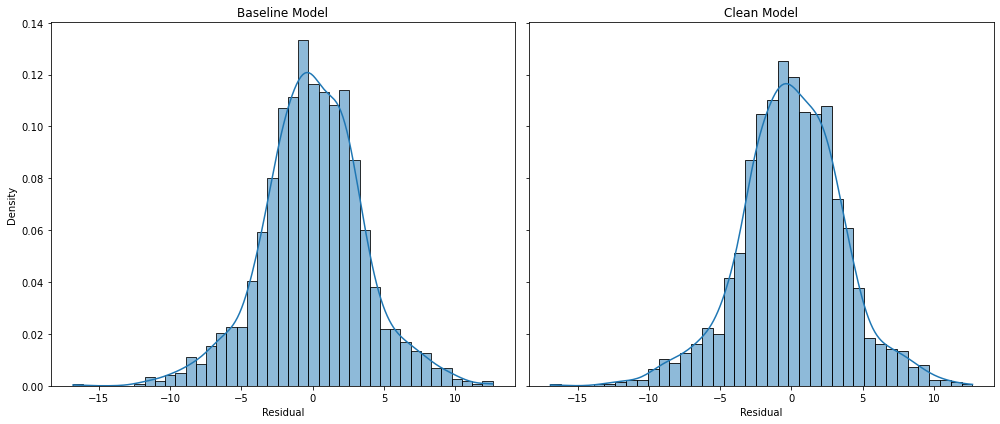

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

baseline_residual = y - lin_reg_model.predict(scaled_X)
clean_residual = y - lin_reg_model_clean.predict(scaled_X_vif)
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
sns.histplot(baseline_residual,
             stat="density",
             kde=True, #Adds curve
             ax=axes[0])
axes[0].set_title('Baseline Model')
axes[0].set_xlabel('Residual')
axes[0].set_ylabel('Density')

sns.histplot(clean_residual,
             stat="density",
             kde=True,
             ax=axes[1])
axes[1].set_title('Clean Model')
axes[1].set_xlabel('Residual')
axes[1].set_ylabel('Density')

plt.tight_layout()
plt.show()

The graphs above does show the error distribution with a bell curve.

### TASK 5
The two variables I will be choosing are HIV/AIDS and Adult mortality. These two interact because HIV/AIDS is a big cause of adult deaths so the effect it has on life expectancy is dependent on how prevalant HIV/AIDS is.

In [74]:
## scaled_X_lasso = scaled_X_vif.copy()
scaled_X_lasso['Adult Mortality x HIV/AIDS'] = scaled_X_lasso['Adult Mortality'] * scaled_X_lasso['HIV/AIDS']

lasso_model = LinearRegression().fit(scaled_X_lasso, y)
r2_lasso = lasso_model.score(scaled_X_lasso, y)
print(f"Lasso r2 score: {r2_lasso:.4f}")
print(f"Baseline r2 score: {r2_score:.4f}")
print(f"Difference in r2: {r2_lasso - r2_score:.4f}")

print("---------------------")
feature_rank_lasso = pd.DataFrame({
    "Feature": scaled_X_lasso.columns,  
    "Coefficient": lasso_model.coef_,
    "Absolute Coefficient": np.abs(lasso_model.coef_) 
}).sort_values('Absolute Coefficient', ascending=False)
print(feature_rank_lasso)

interaction_coef = feature_rank_lasso.set_index('Feature').loc['Adult Mortality x HIV/AIDS', 'Coefficient']
print(f"Interaction Coefficiency: {interaction_coef:.4f}")

Lasso r2 score: 0.8414
Baseline r2 score: 0.8379
Difference in r2: 0.0035
---------------------
                            Feature  Coefficient  Absolute Coefficient
11                         HIV/AIDS    -3.580928              3.580928
1                   Adult Mortality    -2.737112              2.737112
15                        Schooling     2.380178              2.380178
14  Income composition of resources     1.888559              1.888559
3            percentage expenditure     0.782341              0.782341
6                               BMI     0.544240              0.544240
16       Adult Mortality x HIV/AIDS     0.527681              0.527681
0                              Year    -0.466511              0.466511
7                 under-five deaths    -0.459530              0.459530
2                           Alcohol    -0.399657              0.399657
10                       Diphtheria     0.341102              0.341102
12                       Population     0.200809    

The interaction coefficienct is positive. Adding the column did improve the model but only just marginally.